# 01 - Exploratory Data Analysis

**Data:** training set only (24,000 high-value prepaid customers). The test set (6,001) is not opened here, so nothing we see can leak into model decisions.

**Question:** what does a customer look like in June-August *before* they go completely inactive in September?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import config as C
from src import eda

eda.set_style()
eda.clear_old_figures()          # every run rebuilds all figures from scratch
train = pd.read_parquet(C.PROCESSED_DIR / "train.parquet")
print(f"Training set: {train.shape[0]:,} customers x {train.shape[1] - 1} columns")

Training set: 24,000 customers x 157 columns


## 1. How imbalanced is the target?

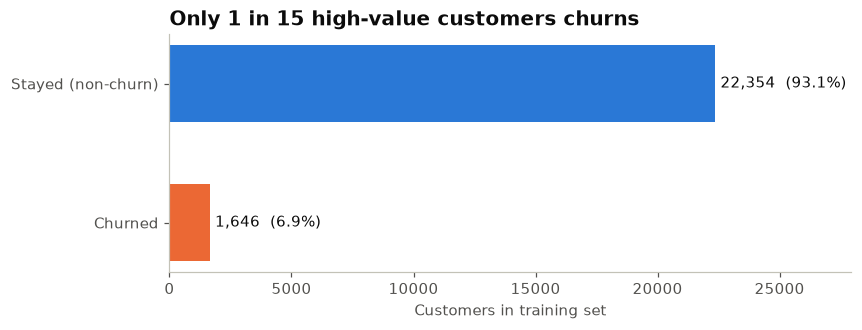

In [2]:
eda.plot_target_balance(train);

Only **6.86%** churn. A model that says "nobody churns" would be 93% accurate and completely useless, so **accuracy will not be used**. We will judge models on PR-AUC, recall and precision of the churn class, and how many churners are caught in the top 10-20% of risk scores.

## 2. Good phase (June-July) vs action phase (August)

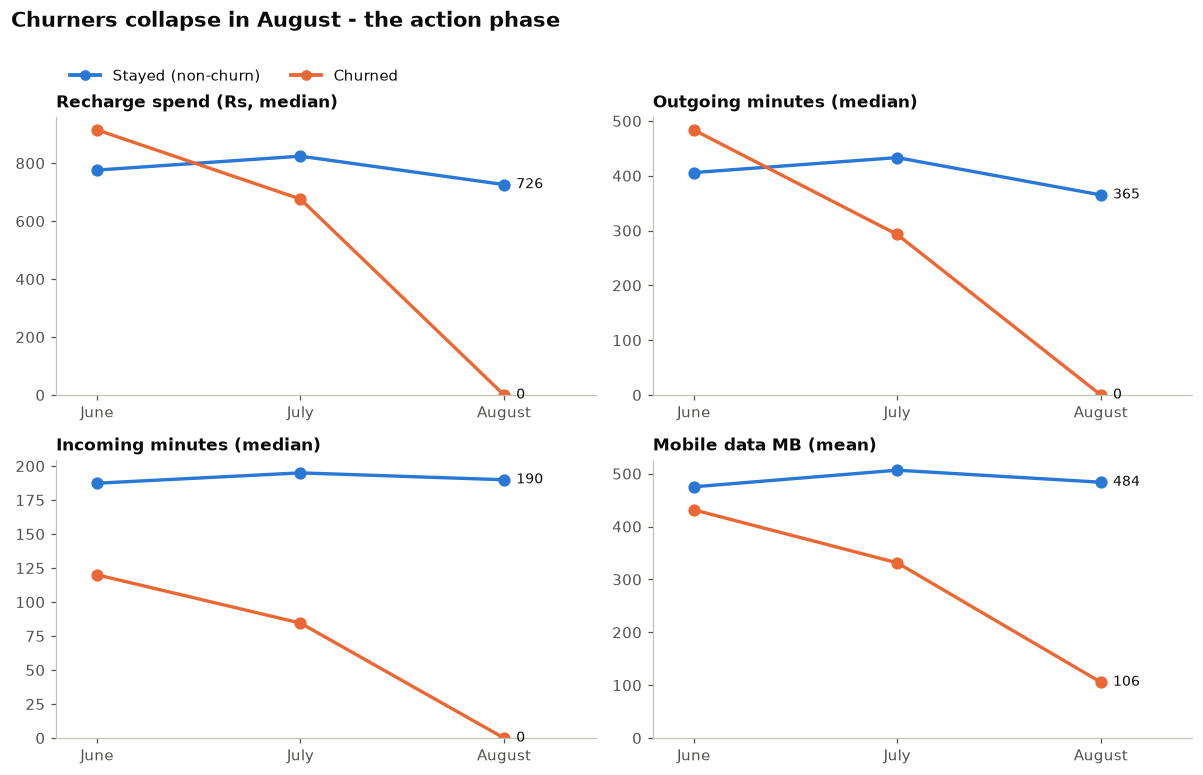

In [3]:
eda.plot_phase_trends(train);

In June churners actually spend and talk **more** than other customers. The decline starts in July and becomes a collapse in August: median recharge, outgoing and incoming minutes all fall to zero. Churn announces itself one month early, which is exactly the window a retention team can act in.

**For feature engineering:** the *change* from June-July to August matters more than any single month's raw value.

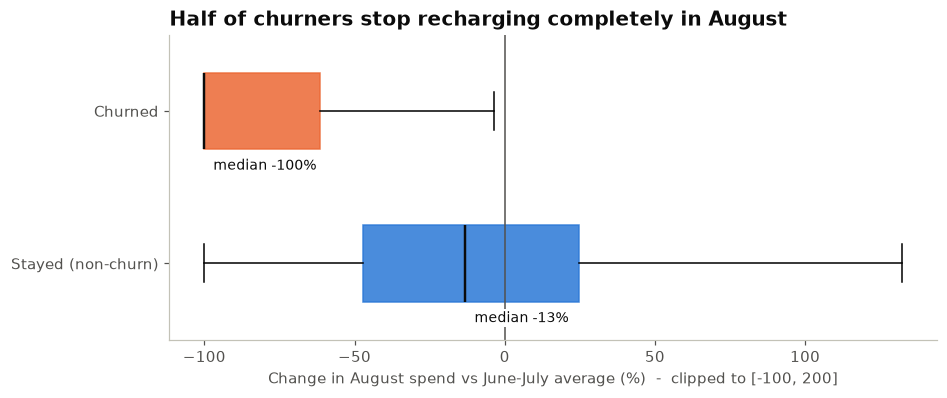

In [4]:
eda.plot_august_spend_change(train);

The median churner's August spend is **-100%** versus their own June-July average, meaning at least half of churners did not recharge at all in August. The median non-churner changes by only -13%. This ratio is one of the strongest signals available and will be built as a feature in Step 3.

## 3. Which single columns separate churners best?

,feature,auc,strength,direction,month
0,loc_ic_mou_8,0.146089,0.707822,lower -> more churn,August
1,total_ic_mou_8,0.148121,0.703758,lower -> more churn,August
2,loc_ic_t2m_mou_8,0.149550,0.700901,lower -> more churn,August
3,loc_og_mou_8,0.173065,0.653869,lower -> more churn,August
4,total_rech_amt_8,0.173189,0.653621,lower -> more churn,August
5,loc_og_t2m_mou_8,0.174590,0.650820,lower -> more churn,August
6,loc_ic_t2t_mou_8,0.175636,0.648728,lower -> more churn,August
7,arpu_8,0.179650,0.640700,lower -> more churn,August
8,loc_og_t2t_mou_8,0.196926,0.606149,lower -> more churn,August
9,last_day_rch_amt_8,0.204254,0.591493,lower -> more churn,August


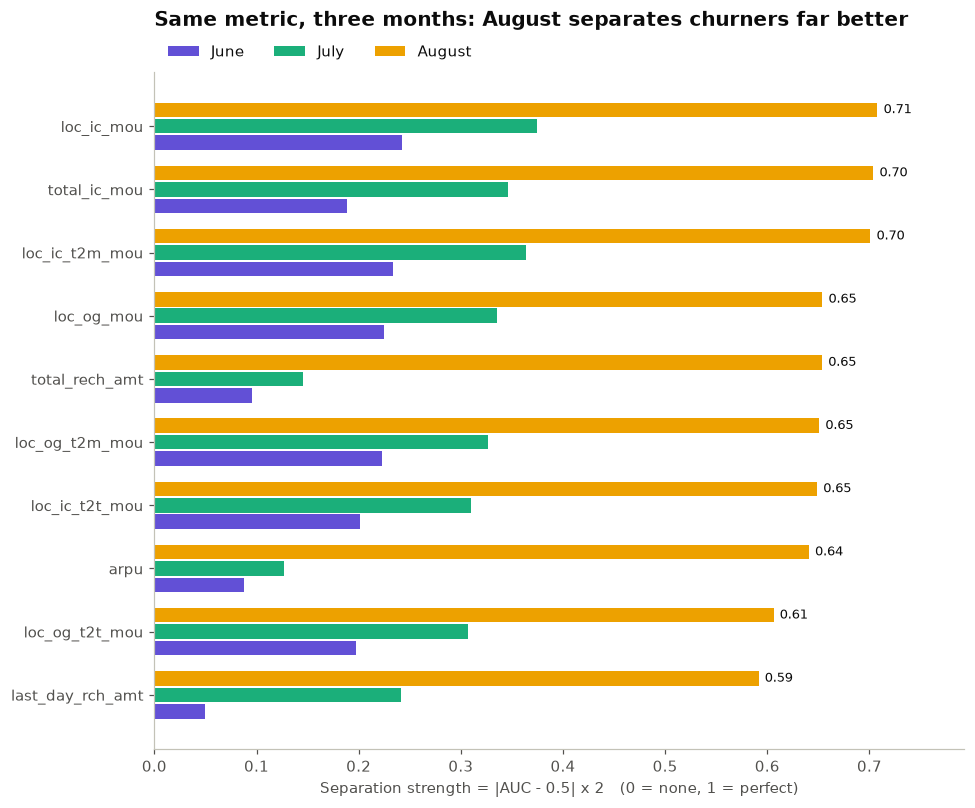

In [5]:
fig, strength = eda.plot_univariate_strength(train)
strength.head(10)

Separation strength is based on AUC, which is rank-based, so heavy skew does not distort it. For every metric the **August** version separates churners far better than June or July, and all top columns point the same way: *lower value -> more churn*. June-July are therefore most useful as each customer's own *baseline* to compare August against.

## 4. Recharge recency, tenure, data usage and revenue

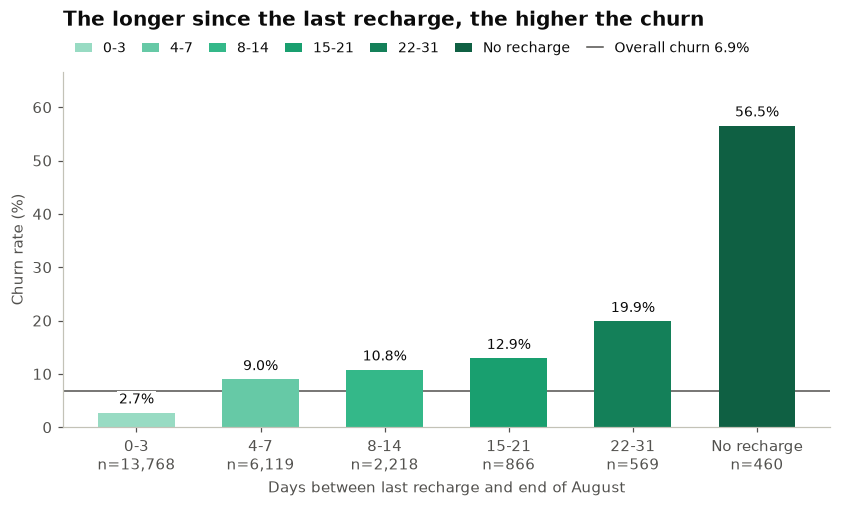

In [6]:
eda.plot_last_recharge(train);

Customers who recharged in the last 3 days of August churn at 2.7%. Customers with no recharge at all in August churn at **56.5%**. Recency of the last recharge is a clean, explainable signal. The raw date will be converted to *days since last recharge*; the old project frequency-encoded the date, which lost this ordering.

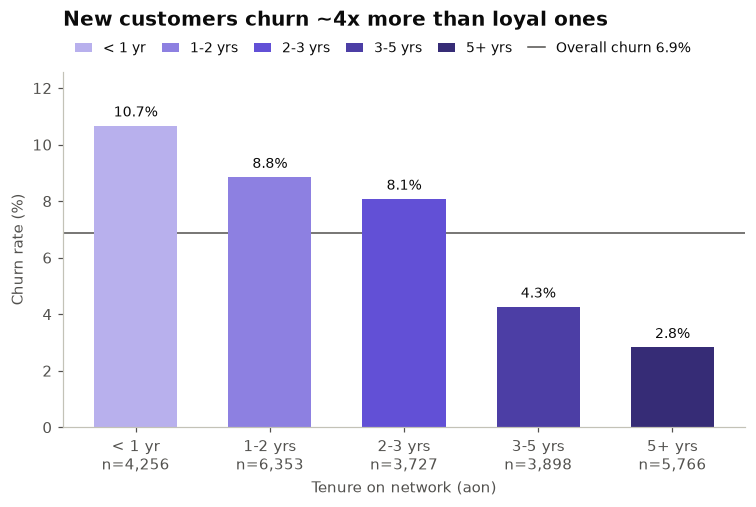

In [7]:
eda.plot_tenure(train);

New customers (under 1 year) churn at 10.7% versus 2.8% for customers with 5+ years. Tenure (`aon`) stays as a feature.

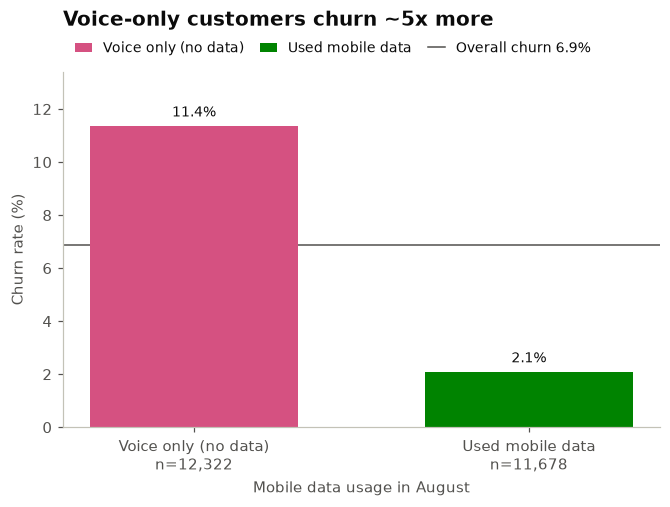

In [8]:
eda.plot_data_usage(train);

Voice-only customers in August churn at 11.4%; customers who used mobile data churn at 2.1%. Data usage reflects engagement with the service.

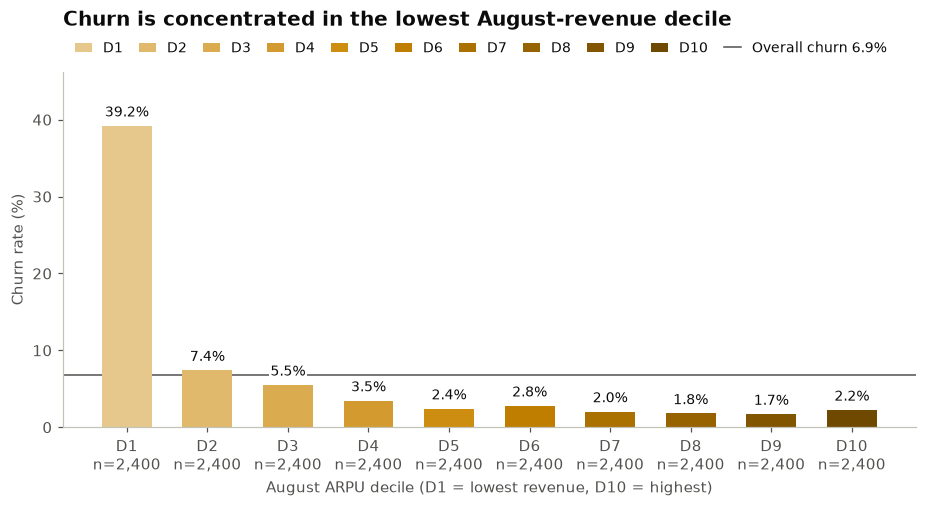

In [9]:
eda.plot_arpu_decile(train);

Churn is concentrated in the lowest August-ARPU decile (39.2%), then drops sharply. This matches the August-collapse story. These customers were high-value in June-July (that is how they were selected), so their low August revenue is a *drop*, not a cheap plan.

## 5. More behaviour signals

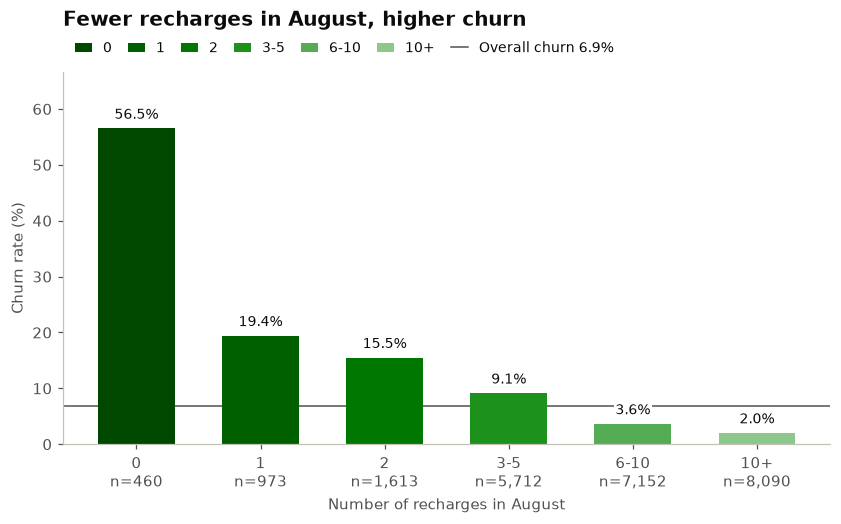

In [10]:
eda.plot_recharge_count(train);

Recharge *frequency* in August tells a smooth story: 56.5% churn with zero recharges, 19.4% with one, falling to 2.0% for customers who recharged more than 10 times. Frequency and recency (section 4) together describe how actively a customer is still paying.

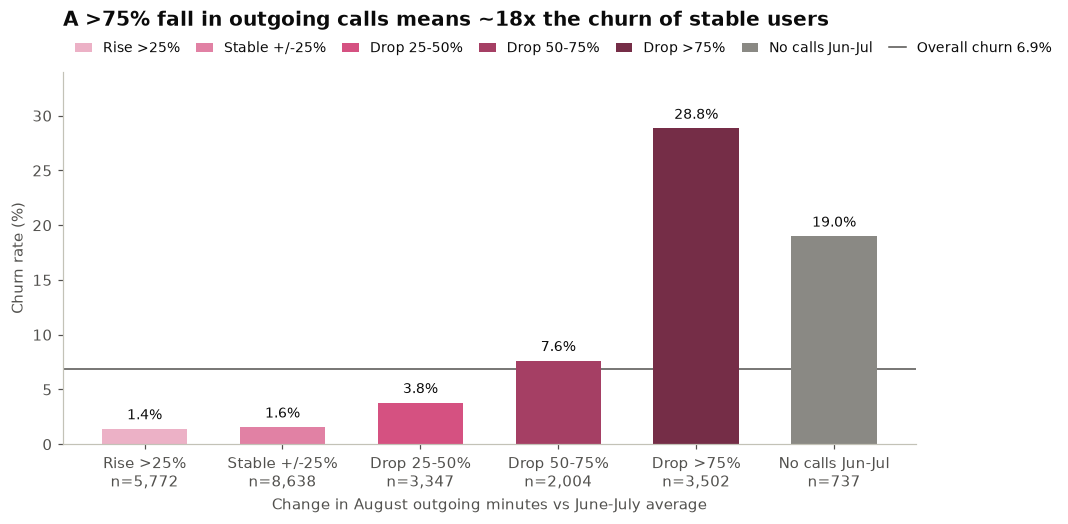

In [11]:
eda.plot_outgoing_change(train);

Customers whose outgoing minutes fell by more than 75% versus their own June-July average churn at **28.8%**, about 18x the 1.6% of stable users. Customers who made no calls in June-July (737) churn at 19.0%: 88.3% of them use mobile data (median 798 MB a month versus 139 MB for everyone else), so they are data-first users whose voice baseline is zero. A percentage change is undefined for them (division by zero), so they get their own flag.

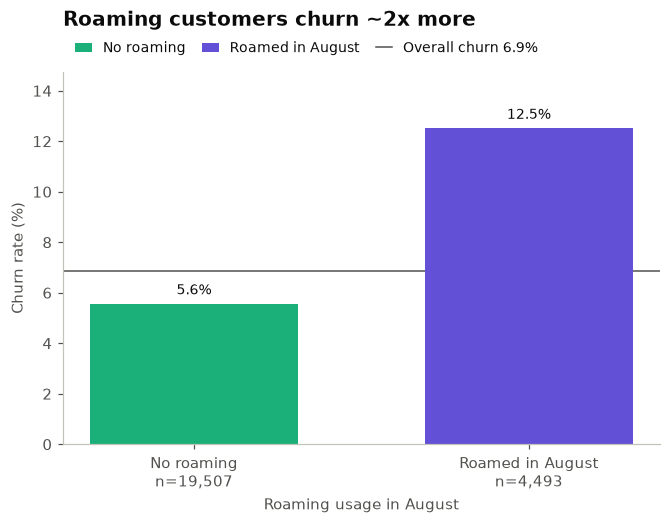

In [12]:
eda.plot_roaming(train);

Customers who used roaming in August churn at 12.5% versus 5.6%. A likely reason is that people who travel or relocate buy a local SIM and stop using this one. Roaming flags will be kept as features.

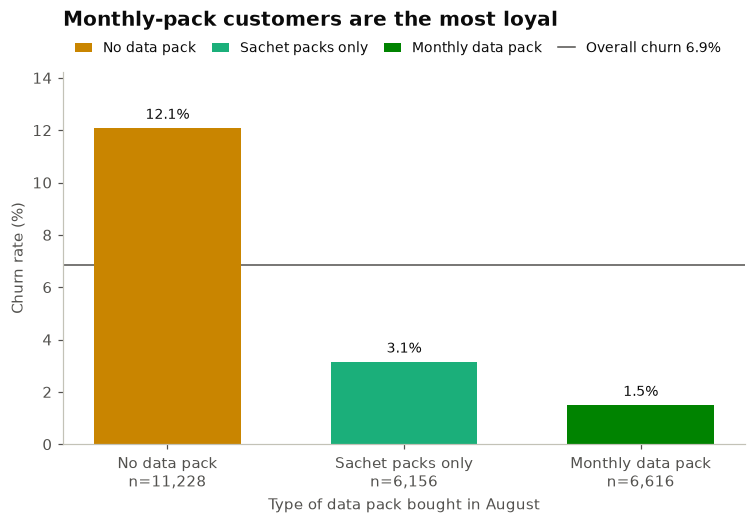

In [13]:
eda.plot_pack_type(train);

Customers on a monthly data pack churn at 1.5%, sachet-only (small top-up packs) at 3.1%, and customers with no data pack at 12.1%. A monthly commitment is a strong loyalty signal.

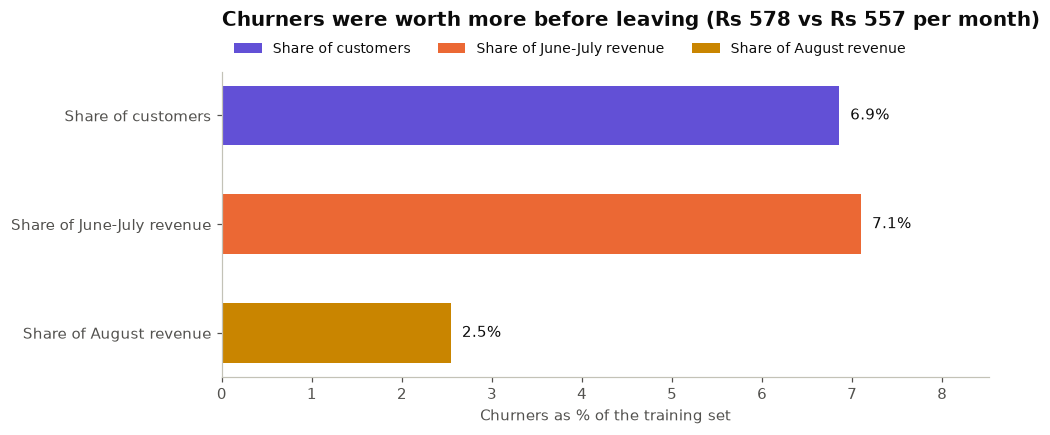

In [14]:
eda.plot_revenue_share(train);

Churners are 6.9% of customers but generated 7.1% of June-July revenue, because they were slightly *more* valuable per month (Rs 578 vs Rs 557). By August their share of revenue has already fallen to 2.5%. This is the business case: the model has to find them while there is still revenue to save.

## 6. Data-quality facts that decide Step 3

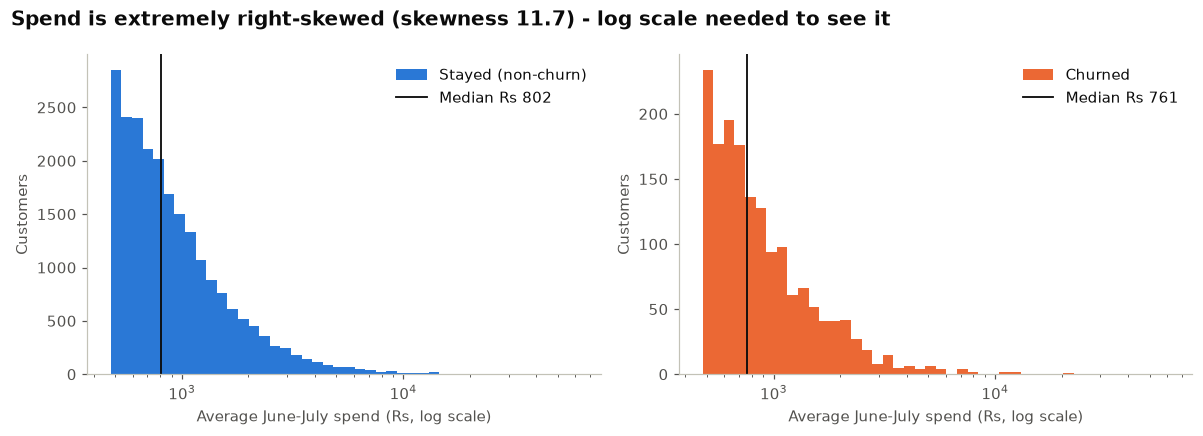

In [15]:
eda.plot_spend_distribution(train);

Average June-July spend has a skewness of about 11.7: the middle half of customers spend Rs 600-1,200 a month, while a few spend tens of thousands. The shape is only readable on a log scale. Tree models are not affected by this skew (they split on order), so no transform is applied for them; a log transform will be used only inside the logistic-regression baseline pipeline.

Columns with >75% zeros (IQR = 0): 39


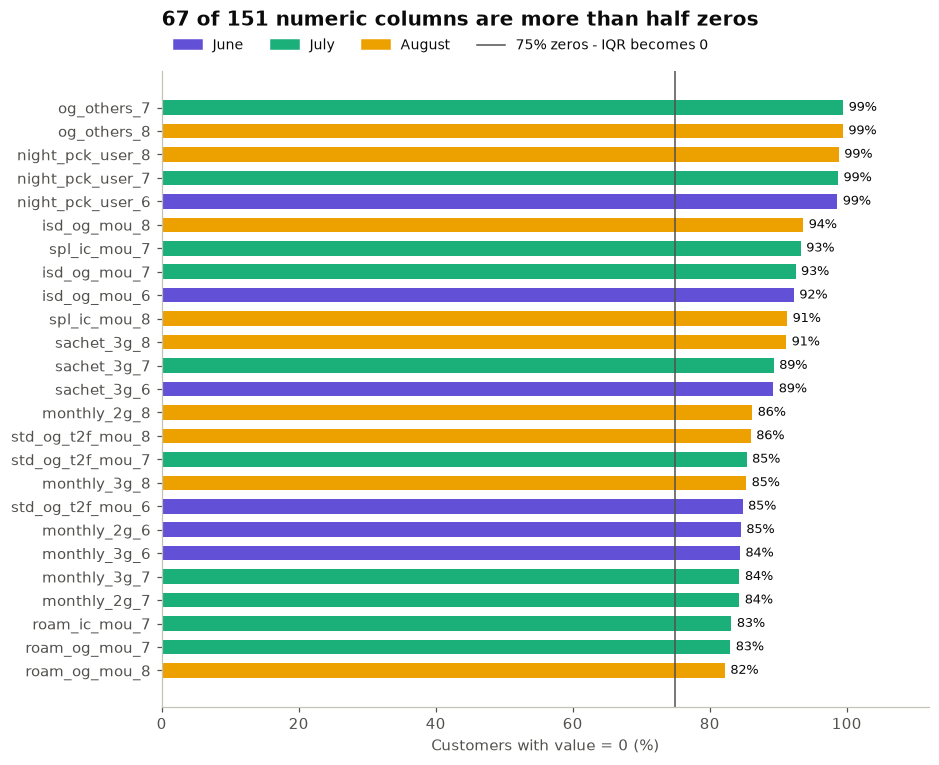

In [16]:
fig, zero_share = eda.plot_zero_share(train)
print(f"Columns with >75% zeros (IQR = 0): {(zero_share > 0.75).sum()}")

Many columns are mostly zeros (roaming, ISD, special numbers, night packs). For any column with more than 75% zeros the IQR is 0, so IQR outlier capping would turn **every** non-zero value into 0 and silently delete the information. That is what happened in the old project. **Decision:** no IQR capping and no log transforms for tree models; trees split on order and are not affected by skew or outliers.

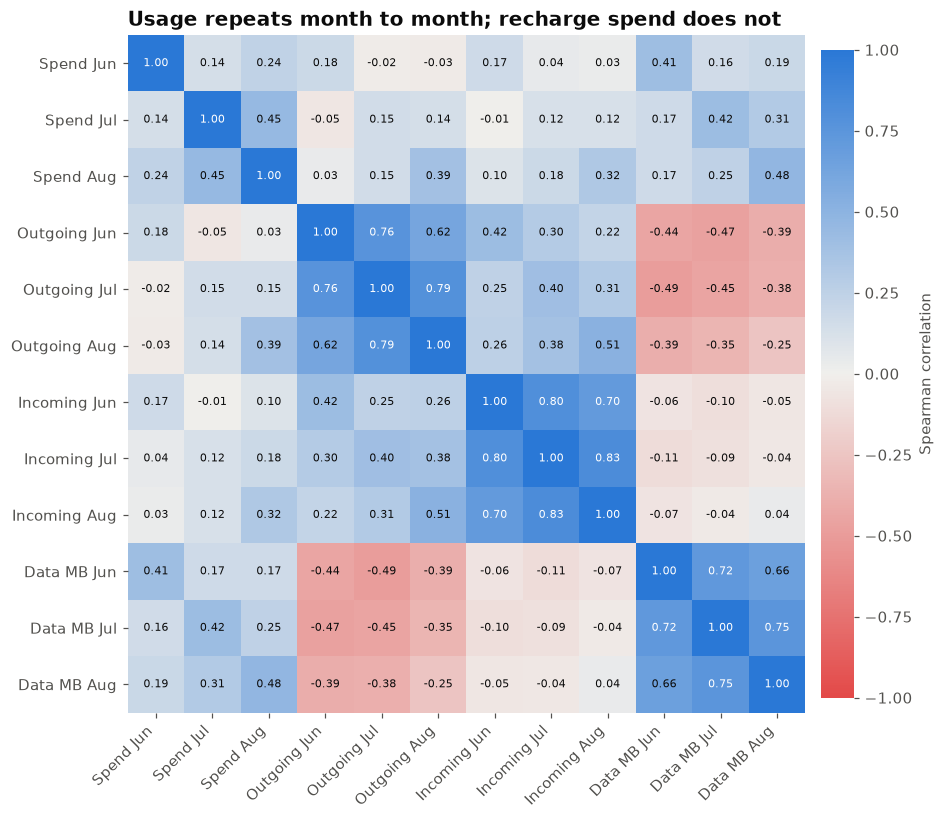

In [17]:
fig, corr = eda.plot_month_correlation(train)

Usage repeats strongly from month to month (outgoing 0.62-0.79, incoming 0.70-0.83, data 0.66-0.75), but **recharge spend does not** (0.14-0.45), because prepaid customers buy packs unevenly. Data usage is negatively related to outgoing minutes (about -0.4), so data users call less. **Decision:** use a June-July *average* as the baseline (it smooths uneven recharges) and build August-vs-baseline change features. VIF-based dropping is not needed for tree models.

## Summary - what Step 3 will build

| Finding | Evidence (train set) | Action in Step 3 |
|---|---|---|
| Strong imbalance | 6.86% churn | Use PR-AUC / recall@top-k, class weights; never plain accuracy |
| August collapse | Churner median spend change -100% (non-churner -13%) | Features: August vs June-July change and ratio for spend, minutes, data, recharge count |
| Recharge recency | 2.7% -> 56.5% churn as recency worsens | `days_since_last_rech_8`, `no_recharge_8` flag (same for data recharge) |
| Tenure | 10.7% (<1 yr) vs 2.8% (5+ yrs) | Keep `aon` |
| Data usage | 2.1% vs 11.4% churn | Data-user flags and data-volume change |
| Recharge frequency | 56.5% (0 recharges) -> 2.0% (10+) | Keep `total_rech_num_8` and its change vs June-July |
| Outgoing-call fall | >75% drop: 28.8% vs stable 1.6% | Outgoing change ratio + `no_calls_good_phase` flag |
| Roaming | 12.5% vs 5.6% | Roaming-in-August flag |
| Pack type | No pack 12.1%, monthly 1.5% | Pack-type flags |
| Revenue at stake | Churners: 7.1% of Jun-Jul revenue, 2.5% of Aug | Rank customers by risk x revenue in Step 5 |
| Heavy skew | Spend skewness ~11.7 | No transform for trees; log only in the linear baseline |
| Zero-heavy columns | Many columns >75% zeros | No IQR capping, no log transform for trees |
| Month-to-month pattern | Usage correlated 0.62-0.83; spend only 0.14-0.45 | June-July average as baseline, change features instead of VIF pruning |
